# Golden model — pow2-weight CNN (iter_p2w4a6_in4)

Mô hình **số nguyên, bit-exact** của inference engine, dựa theo paper
*Sanjeet, Sahoo, Fujita — "Energy-Efficient FPGA Implementation of Power-of-2 Weights-Based CNNs With Low Bit-Precision Input Images", IEEE TCAS-II 2023*,
áp dụng cho checkpoint `runs/iter_p2w4a6_in4/model.pt` đã train bằng `main.py`.

Mục đích: làm **reference cho RTL**. Mọi phép toán chỉ dùng số nguyên: dịch bit, cộng, một phép nhân hằng số mỗi kênh (BN), clamp và so sánh.
Mỗi bước đều được đối chiếu với mô hình PyTorch, và cuối notebook xuất **test vector (.hex)**.

| Bước trong notebook | Mục tương ứng trong paper | Phần cứng |
|---|---|---|
| 1. Lượng tử ảnh đầu vào | II-A: giữ MSB của pixel | ghi ảnh vào RAM 0 |
| 2. Trọng số pow2 → mã 4 bit | II-B: $w_q=\mathrm{sign}(w)\,2^{\mathrm{round}(\log_2\lvert w\rvert)}$, mã = 1 bit dấu + 3 bit số mũ | ROM trọng số |
| 3. Prune → bỏ kênh | Algorithm 1 (prune filter) | số PE/kênh thực tế |
| 4. Clip activation pow2, 6 bit | II-B: activation lượng tử tuyến tính 6 bit | |
| 5. Gộp BN → nhân + bias + shift | *(không có trong paper: paper không dùng BN)* | 1 hệ số nhân + 1 bias mỗi kênh |
| 6. Conv 3×3 bằng dịch bit | III-A, Fig. 5: dot-product 9 tap → accumulator qua `d` kênh vào | PE |
| 7. Requant → 6 bit, ReLU, maxpool | III-A: bias, ReLU, cắt về 6 bit; pooling block | |
| 8. GAP + FC + quyết định | III-A: FC adder tree + FC decision block | so sánh với ngưỡng |

**Khác với paper:** ảnh xám 4 bit (paper dùng RGB 3 bit/kênh), 2 lớp (`no_person` / `person`), có BatchNorm, dùng global average pool trước FC, và ngưỡng quyết định là một số nguyên (đã gộp bias của FC và hệ số thang đo).

In [1]:
import os, sys, json, math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

HERE = os.path.abspath('')                 # commit_folder/
sys.path.insert(0, HERE)
from qnn.config import IN_BITS, ABITS, W_EMIN, W_EMAX, parse_arch   # constants only
from qnn.data import load_folder, prep                             # image loading + float input (for reference)
from qnn.engine import load_ckpt                                   # PyTorch reference model
from qnn.quant import pow2_weight

CKPT     = os.path.join(HERE, 'runs/iter_p2w4a6_in4/model.pt')
TEST_DIR = os.path.join(os.path.dirname(HERE), 'human_detection_dataset_split')   # {no_person,person}/
OUT_DIR  = os.path.join(HERE, 'golden_out')
SAMPLE_IDX = 0          # which test image to trace layer by layer / export

FRAC   = -W_EMIN        # 7 : weight 2^-e  ==  (x << (7-e)) with 7 fractional bits
AMAX   = 2**ABITS - 1   # 63: 6-bit activation
INMAX  = 2**IN_BITS - 1 # 15: 4-bit input pixel
M_BITS = 16             # signed width of the BN-folded multiplier
BN_EPS = 1e-5

np.set_printoptions(linewidth=150)
plt.rcParams['figure.dpi'] = 90
print('IN_BITS', IN_BITS, ' ABITS', ABITS, ' weight exponents', W_EMIN, '..', W_EMAX, ' M_BITS', M_BITS)

IN_BITS 4  ABITS 6  weight exponents -7 .. -1  M_BITS 16


## 0. Đọc checkpoint
`state_dict` chứa trọng số float (sẽ được lượng tử ngay bên dưới), tham số BN, `clip` của từng activation, mask prune và `fc_scale`. `thr` là ngưỡng quyết định đã tune trên tập calib.

In [2]:
ck = torch.load(CKPT, map_location='cpu', weights_only=False)
sd = {k: v.detach().double() for k, v in ck['state_dict'].items()}
arch = parse_arch(ck['arch'])
nL = len(arch)
pools = [p for _, p in arch]
kept = [np.nonzero(sd[f'mask{i}'].numpy())[0] for i in range(nL)]   # indices of surviving filters
THR = float(ck['thr'])
print('arch      ', ck['arch'], '->', arch)
print('kept      ', [len(k) for k in kept], 'of', [c for c, _ in arch])
print('thr       ', THR)
print('fc_scale  ', float(sd['fc_scale']))
for i in range(nL):
    print(f'layer {i}: pruned filters', np.nonzero(sd[f"mask{i}"].numpy() == 0)[0].tolist())

arch       8p-16p-24-32p-32 -> [(8, True), (16, True), (24, False), (32, True), (32, False)]
kept       [8, 16, 23, 31, 29] of [8, 16, 24, 32, 32]
thr        0.01921778917312622
fc_scale   3.066035032272339
layer 0: pruned filters []
layer 1: pruned filters []
layer 2: pruned filters [12]
layer 3: pruned filters [21]
layer 4: pruned filters [3, 6, 27]


## 1. Lượng tử ảnh đầu vào (paper II-A)
Ảnh 8 bit chỉ giữ `IN_BITS` = 4 bit cao nhất: $x_q = x_{u8} \gg (8-4)$, $x_q\in[0,15]$.
Mô hình float thấy giá trị $x_q/15$. Golden model dùng thẳng số nguyên $x_q$, còn hệ số $1/15$ được gộp vào hệ số BN của layer 0.

test set (921, 64, 64)  person 559  no_person 362


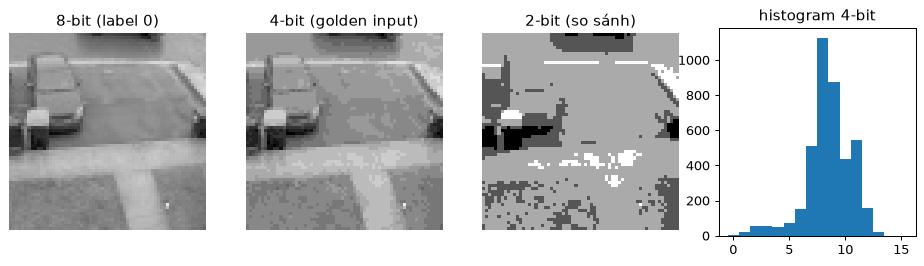

8x8 góc trên-trái của ảnh 4-bit:
 [[9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 9]
 [9 9 9 9 9 9 9 7]]


In [3]:
x_u8, y_all = load_folder(TEST_DIR)                       # (N,64,64) uint8, labels 0/1
X_q = (x_u8.astype(np.int64) >> (8 - IN_BITS))[:, None]   # (N,1,64,64) int 0..15
print('test set', x_u8.shape, ' person', int(y_all.sum()), ' no_person', int((y_all == 0).sum()))

img8, lab = x_u8[SAMPLE_IDX], y_all[SAMPLE_IDX]
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
ax[0].imshow(img8, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'8-bit (label {lab})')
ax[1].imshow(X_q[SAMPLE_IDX, 0], cmap='gray', vmin=0, vmax=INMAX); ax[1].set_title(f'{IN_BITS}-bit (golden input)')
ax[2].imshow(img8 >> 6, cmap='gray', vmin=0, vmax=3); ax[2].set_title('2-bit (so sánh)')
ax[3].hist(X_q[SAMPLE_IDX].ravel(), bins=np.arange(INMAX + 2) - .5); ax[3].set_title('histogram 4-bit')
for a in ax[:3]: a.axis('off')
plt.show()
print('8x8 góc trên-trái của ảnh 4-bit:\n', X_q[SAMPLE_IDX, 0, :8, :8])

## 2. Trọng số power-of-2 → mã 4 bit (paper II-B)
$w_q = \mathrm{sign}(w)\cdot 2^{\mathrm{round}(\log_2|w|)}$, $|w_q|\in\{2^{-1},\dots,2^{-7}\}$; $|w|<2^{-7}\Rightarrow 0$. Có 15 giá trị.

Mã 4 bit: `[s e2 e1 e0]`, `s` = dấu, `e` = số bit dịch phải (1..7), `e=0` → trọng số 0. Ví dụ $2^{-5}$ = `0101`, $-2^{-3}$ = `1011`.

Phần cứng: $x\cdot 2^{-e} = x \gg e$. Để không mất bit, golden giữ 7 bit thập phân: $x\cdot 2^{-e}\cdot 2^{7} = x \ll (7-e)$.
Vậy **trọng số nguyên** là $w_{int} = \pm 2^{7-e}\in\{0,\pm1,\pm2,\dots,\pm64\}$, và giá trị thật là $w_q = w_{int}/2^7$.

Hàm bên dưới dùng đúng phép tính float32 của `qnn.quant.pow2_weight` (lúc train), nên mã thu được trùng hoàn toàn.

In [4]:
def pow2_code(w):
    '''float weights -> (sign 0/1, e 0..7, code 4-bit, w_int = ±2^(7-e) or 0). Same rule as qnn.quant.pow2_weight.'''
    w = torch.as_tensor(np.asarray(w), dtype=torch.float32)
    a = w.abs()
    ex = torch.round(torch.log2(a.clamp(min=2.0**W_EMIN / 2))).clamp(W_EMIN, W_EMAX)   # -7..-1
    zero = a < 2.0**W_EMIN
    e = torch.where(zero, torch.zeros_like(ex), -ex).numpy().astype(np.int64)        # 1..7, 0 = zero
    s = ((w < 0) & ~zero).numpy().astype(np.int64)
    code = (s << 3) | e
    w_int = np.where(e == 0, 0, (1 - 2 * s) * (1 << (FRAC - np.maximum(e, 1))))
    return s, e, code, w_int

def code_to_wint(code):
    s, e = code >> 3, code & 7
    return np.where(e == 0, 0, (1 - 2 * s) * (1 << (FRAC - np.maximum(e, 1))))

# ---- conv weights: quantize, then compact away pruned output channels (and the matching input channels)
W_code, W_int = [], []
for i in range(nL):
    w = sd[f'convs.{i}.weight'].float()
    s, e, c4, wi = pow2_code(w)
    assert np.array_equal(wi / 2.0**FRAC, pow2_weight(w).detach().double().numpy()), 'mismatch vs training quantizer'
    assert np.array_equal(code_to_wint(c4), wi)
    cin_keep = np.arange(1) if i == 0 else kept[i - 1]
    W_code.append(c4[kept[i]][:, cin_keep])
    W_int.append(wi[kept[i]][:, cin_keep])

# ---- FC weights (also pow2), keep only inputs from surviving channels of the last conv
_, _, FC_code, FC_int = pow2_code(sd['fc.weight'].float())
FC_code, FC_int = FC_code[:, kept[-1]], FC_int[:, kept[-1]]

print(f"{'layer':6}{'shape (compact)':>18}{'#params':>9}{'zero %':>8}   exponent histogram e=1..7 (|w|=2^-e)")
for i in range(nL):
    e = W_code[i] & 7
    print(f"{i:<6}{str(W_code[i].shape):>18}{W_code[i].size:>9}{100 * (e == 0).mean():>7.1f}%   {np.bincount(e.ravel(), minlength=8)[1:].tolist()}")
e = FC_code & 7
print(f"{'fc':<6}{str(FC_code.shape):>18}{FC_code.size:>9}{100 * (e == 0).mean():>7.1f}%   {np.bincount(e.ravel(), minlength=8)[1:].tolist()}")
print('total params (compact):', sum(w.size for w in W_code) + FC_code.size,
      ' -> weight memory', 4 * (sum(w.size for w in W_code) + FC_code.size), 'bit')

layer    shape (compact)  #params  zero %   exponent histogram e=1..7 (|w|=2^-e)
0           (8, 1, 3, 3)       72    1.4%   [28, 18, 16, 4, 4, 1, 0]
1          (16, 8, 3, 3)     1152    2.7%   [226, 322, 286, 157, 85, 34, 11]
2         (23, 16, 3, 3)     3312    1.8%   [690, 1024, 768, 413, 214, 106, 37]
3         (31, 23, 3, 3)     6417    2.1%   [1490, 2079, 1359, 688, 391, 213, 61]
4         (29, 31, 3, 3)     8091    2.0%   [1940, 2535, 1740, 931, 468, 233, 81]
fc               (2, 29)       58    0.0%   [42, 16, 0, 0, 0, 0, 0]
total params (compact): 19102  -> weight memory 76408 bit


float w :
 [[-0.0365  0.4988 -0.1738]
 [-0.44    0.2007 -0.2232]
 [-0.14    0.4964 -0.2032]]
code    :
 [['1101' '0001' '1011']
 ['1001' '0010' '1010']
 ['1011' '0001' '1010']]
w_int   :
 [[ -4  64 -16]
 [-64  32 -32]
 [-16  64 -32]]    (w_q = w_int / 128)


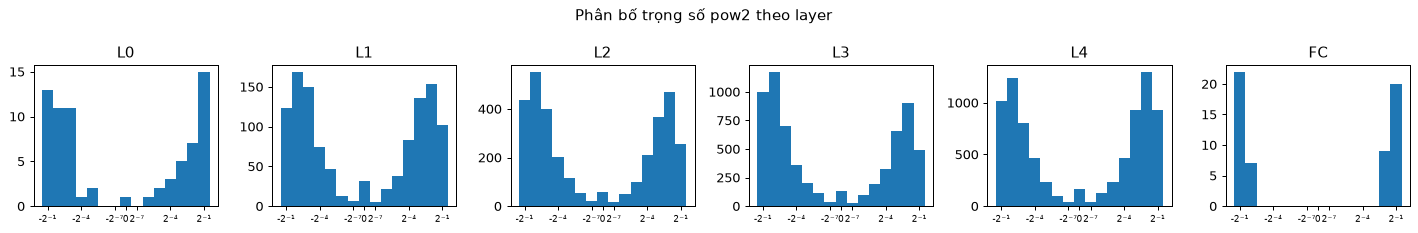

In [5]:
# Filter 0 of layer 0: float weight -> code (binary) -> w_int
w0 = sd['convs.0.weight'][kept[0][0], 0].numpy()
print('float w :\n', np.round(w0, 4))
print('code    :\n', np.vectorize(lambda v: format(v, '04b'))(W_code[0][0, 0]))
print('w_int   :\n', W_int[0][0, 0], '   (w_q = w_int / 128)')

fig, ax = plt.subplots(1, nL + 1, figsize=(16, 2.6), sharey=False)
for i in range(nL + 1):
    c = (W_code[i] if i < nL else FC_code).ravel()
    val = np.where((c & 7) == 0, 0, (1 - 2 * (c >> 3)) * (8 - (c & 7)))   # signed "level": ±(8-e)
    ax[i].hist(val, bins=np.arange(-7.5, 8.5, 1)); ax[i].set_title(f'L{i}' if i < nL else 'FC')
    ax[i].set_xticks([-7, -4, -1, 0, 1, 4, 7]); ax[i].set_xticklabels(['-2⁻¹', '-2⁻⁴', '-2⁻⁷', '0', '2⁻⁷', '2⁻⁴', '2⁻¹'], fontsize=7)
plt.suptitle('Phân bố trọng số pow2 theo layer'); plt.tight_layout(); plt.show()

## 3. Activation 6 bit với clip là lũy thừa của 2
`ActQ`: $c=2^{\mathrm{round}(\log_2|clip|)}$, $a = \mathrm{round}(\min(\mathrm{ReLU}(y),c)/c\cdot 63)\cdot c/63$.
Golden lưu **mã 6 bit** $q\in[0,63]$, giá trị thật là $q\cdot s$ với $s=c/63$.

In [6]:
C_clip = [2.0 ** int(torch.round(torch.log2(torch.tensor(abs(float(sd[f'acts.{i}.clip'])), dtype=torch.float32))).item())
          for i in range(nL)]
S_act = [c / AMAX for c in C_clip]              # real value of one activation LSB
for i in range(nL):
    print(f"layer {i}: clip param {float(sd[f'acts.{i}.clip']):.4f} -> c = {C_clip[i]:g}   LSB s = c/63 = {S_act[i]:.5f}")

layer 0: clip param 6.1713 -> c = 8   LSB s = c/63 = 0.12698
layer 1: clip param 5.2505 -> c = 4   LSB s = c/63 = 0.06349
layer 2: clip param 3.6569 -> c = 4   LSB s = c/63 = 0.06349
layer 3: clip param 2.6967 -> c = 2   LSB s = c/63 = 0.03175
layer 4: clip param 4.0081 -> c = 4   LSB s = c/63 = 0.06349


## 4. Gộp BatchNorm → hệ số nhân nguyên + bias + dịch (requant)
Với layer $i$, accumulator nguyên $acc$ (đơn vị $2^{-7}\cdot s_{in}$, trong đó $s_{in}=1/15$ ở layer 0 và $s_{in}=c_{i-1}/63$ ở các layer sau):

$$z = acc\cdot 2^{-7}s_{in},\qquad y=\gamma\frac{z-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta,\qquad q=\mathrm{clamp}\Big(\mathrm{round}\big(y\cdot\tfrac{63}{c_i}\big),0,63\Big)$$

Gom lại thành $q=\mathrm{clamp}(\mathrm{round}(A\cdot acc + B),0,63)$ với
$A=\frac{\gamma}{\sqrt{\sigma^2+\epsilon}}\,s_{in}\,2^{-7}\,\frac{63}{c_i}$, $B=\big(\beta-\frac{\gamma\mu}{\sqrt{\sigma^2+\epsilon}}\big)\frac{63}{c_i}$.

**Fixed-point (phần cứng):** $M=\mathrm{round}(A\,2^{SH})$ là số có dấu `M_BITS` bit, $B_q=\mathrm{round}(B\,2^{SH})+2^{SH-1}$ (cộng sẵn số làm tròn), rồi
$$q=\mathrm{clamp}\big((acc\cdot M + B_q)\gg SH,\ 0,\ 63\big)$$
Phép $\gg$ là dịch phải số học (floor). Mỗi layer chọn $SH$ lớn nhất sao cho $|M|<2^{M\_BITS-1}$. Phần ReLU và cắt 6 bit trong paper (III-A) chính là bước clamp này.

In [7]:
def sbits(lo, hi):
    '''bits of a two's-complement number able to hold [lo, hi]'''
    m = max(-int(lo), int(hi) + 1, 1)
    return int(math.ceil(math.log2(m))) + 1

BN = []   # per layer: dict(A, B, M, Bq, SH)
for i in range(nL):
    k = kept[i]
    g, b = sd[f'bns.{i}.weight'].numpy()[k], sd[f'bns.{i}.bias'].numpy()[k]
    mu, var = sd[f'bns.{i}.running_mean'].numpy()[k], sd[f'bns.{i}.running_var'].numpy()[k]
    inv = g / np.sqrt(var + BN_EPS)
    s_in = 1.0 / INMAX if i == 0 else S_act[i - 1]
    A = inv * s_in * 2.0**-FRAC * AMAX / C_clip[i]
    B = (b - inv * mu) * AMAX / C_clip[i]
    SH = int(math.floor(math.log2((2**(M_BITS - 1) - 1) / np.abs(A).max())))
    M = np.round(A * 2.0**SH).astype(np.int64)
    Bq = np.round(B * 2.0**SH).astype(np.int64) + (1 << (SH - 1))
    BN.append(dict(A=A, B=B, M=M, Bq=Bq, SH=SH))
    print(f"layer {i}: SH={SH:2d}  M in [{M.min():6d},{M.max():6d}] ({sbits(M.min(), M.max())} b)   "
          f"Bq in [{Bq.min():12d},{Bq.max():12d}] ({sbits(Bq.min(), Bq.max())} b)   "
          f"neg-gamma channels: {int((M < 0).sum())}")
BQ_BITS = max(sbits(d['Bq'].min(), d['Bq'].max()) for d in BN)
print('Bq width needed:', BQ_BITS, 'bit')

layer 0: SH=19  M in [  8899, 26307] (16 b)   Bq in [    -2918462,     4604802] (24 b)   neg-gamma channels: 0
layer 1: SH=21  M in [ 10129, 26847] (16 b)   Bq in [   -13635337,    40648708] (27 b)   neg-gamma channels: 0
layer 2: SH=22  M in [  8387, 16901] (16 b)   Bq in [   -42795154,   157474367] (29 b)   neg-gamma channels: 0
layer 3: SH=22  M in [ 13949, 30203] (16 b)   Bq in [  -151839869,   269206370] (30 b)   neg-gamma channels: 0
layer 4: SH=23  M in [ 13506, 20184] (16 b)   Bq in [  -342061936,   211522399] (30 b)   neg-gamma channels: 0
Bq width needed: 30 bit


## 5. Các khối của golden model
* `conv3x3_int`: 9 tap; mỗi tap là $\pm(x\ll(7-e))$ (Fig. 5), cộng qua `Cin` kênh vào (accumulator, paper III-A). Padding = 0, stride 1.
* `requant`: `'fixed'` = phần cứng ($M$, $B_q$, $SH$); `'ideal'` = làm tròn float64, dùng để tách sai số do fixed-point gây ra.
* `maxpool2`: so sánh 2×2 trên mã 6 bit (đúng tuyệt đối, vì phép requant đơn điệu và có clamp).
* Đầu ra: $S_c=\sum_{h,w} q_c$ (GAP, bỏ phép chia), $acc^{fc}_j=\sum_c w^{fc}_{int,j,c}\,S_c$, $D=acc^{fc}_1-acc^{fc}_0$; **person** khi $D > T$.

In [8]:
def conv3x3_int(x, w_int):
    '''x (N,Cin,H,W) int64 >= 0, w_int (Cout,Cin,3,3) in {0, ±1..±64}. Returns acc (N,Cout,H,W) int64.
    w_int * x is a shift: x << (7-e) with sign; einsum = adder tree over 9 taps x Cin.'''
    N, C, H, W = x.shape
    xp = np.pad(x, ((0, 0), (0, 0), (1, 1), (1, 1)))
    acc = np.zeros((N, w_int.shape[0], H, W), np.int64)
    for ky in range(3):
        for kx in range(3):
            acc += np.einsum('oc,nchw->nohw', w_int[:, :, ky, kx], xp[:, :, ky:ky + H, kx:kx + W], optimize=True)
    return acc

def requant(acc, bn, mode='fixed'):
    if mode == 'fixed':
        M, Bq = bn['M'][None, :, None, None], bn['Bq'][None, :, None, None]
        y = (acc * M + Bq) >> bn['SH']
    else:
        y = np.round(acc * bn['A'][None, :, None, None] + bn['B'][None, :, None, None])
    return np.clip(y, 0, AMAX).astype(np.int64)

def maxpool2(x):
    N, C, H, W = x.shape
    return x.reshape(N, C, H // 2, 2, W // 2, 2).max(axis=(3, 5))

# ---- integer decision threshold: score = fc_scale*(K*D + (b1-b0)) > thr  <=>  D > (thr/fc_scale - (b1-b0)) / K
FC_SCALE = float(sd['fc_scale'])
assert FC_SCALE > 0, 'fc_scale must be positive for the folded threshold'
b_fc = sd['fc.bias'].numpy()
HW_LAST = None   # set after the first forward (spatial size of the last conv output)

def fc_K(hw):    # real value of one LSB of D
    return S_act[-1] / hw / 2.0**FRAC

def golden_forward(xq, mode='fixed', trace=False):
    '''xq (N,1,64,64) int 0..15  ->  dict with D, decision and (if trace) every intermediate.'''
    t = dict(acc=[], q=[], out=[])
    x = xq.astype(np.int64)
    for i in range(nL):
        acc = conv3x3_int(x, W_int[i])
        q = requant(acc, BN[i], mode)
        x = maxpool2(q) if pools[i] else q
        if trace:
            t['acc'].append(acc); t['q'].append(q); t['out'].append(x)
        else:
            t['acc'].append((acc.min(), acc.max()))
    hw = x.shape[2] * x.shape[3]
    S = x.sum(axis=(2, 3))                        # (N, C) GAP without the divide
    acc_fc = S @ FC_int.T                         # (N, 2)
    D = acc_fc[:, 1] - acc_fc[:, 0]
    T = math.floor((THR / FC_SCALE - (b_fc[1] - b_fc[0])) / fc_K(hw))
    T0 = math.floor((0.0 / FC_SCALE - (b_fc[1] - b_fc[0])) / fc_K(hw))
    logits = FC_SCALE * (acc_fc * fc_K(hw) + b_fc[None])   # float, only for comparison
    t.update(S=S, acc_fc=acc_fc, D=D, T=T, T0=T0, hw=hw, logits=logits,
             pred=(D > T).astype(np.int64), pred_argmax=(D > T0).astype(np.int64))
    return t

## 6. Chạy 1 ảnh, theo dõi từng layer
Với mỗi layer: kích thước, khoảng giá trị của accumulator và số bit cần dùng (paper: tích 14 bit, dot-product 18 bit, accumulator 25 bit), khoảng giá trị đầu ra 6 bit và tỉ lệ số 0 (độ thưa).

In [9]:
g1 = golden_forward(X_q[SAMPLE_IDX:SAMPLE_IDX + 1], 'fixed', trace=True)
print(f"image #{SAMPLE_IDX}, label {y_all[SAMPLE_IDX]}")
print(f"{'layer':6}{'in':>14}{'acc range':>22}{'acc bits':>9}{'out (after pool)':>18}{'q range':>10}{'zeros %':>9}{'sat63 %':>9}")
shape_in = X_q[SAMPLE_IDX:SAMPLE_IDX + 1].shape
for i in range(nL):
    a, q, o = g1['acc'][i], g1['q'][i], g1['out'][i]
    print(f"{i:<6}{str(shape_in[1:]):>14}{f'[{a.min()}, {a.max()}]':>22}{sbits(a.min(), a.max()):>9}"
          f"{str(o.shape[1:]):>18}{f'[{q.min()},{q.max()}]':>10}{100 * (q == 0).mean():>8.1f}%{100 * (q == AMAX).mean():>8.1f}%")
    shape_in = o.shape
print(f"\nGAP sums S (len {g1['S'].shape[1]}):", g1['S'][0].tolist())
print('acc_fc  :', g1['acc_fc'][0].tolist(), '  D = acc1 - acc0 =', int(g1['D'][0]))
print('T (tuned thr) =', g1['T'], '   T0 (argmax) =', g1['T0'])
print('decision:', 'person' if g1['pred'][0] else 'no_person', ' (label', 'person)' if y_all[SAMPLE_IDX] else 'no_person)')

image #0, label 0
layer             in             acc range acc bits  out (after pool)   q range  zeros %  sat63 %
0        (1, 64, 64)         [-1960, 1536]       12       (8, 32, 32)    [0,46]    71.8%     0.0%
1        (8, 32, 32)       [-13988, 11729]       15      (16, 16, 16)    [0,63]    51.2%     0.0%
2       (16, 16, 16)       [-26175, 16232]       16      (23, 16, 16)    [0,45]    41.9%     0.0%
3       (23, 16, 16)       [-27322, 17656]       16        (31, 8, 8)    [0,55]    78.3%     0.0%
4         (31, 8, 8)       [-29625, 43532]       17        (29, 8, 8)    [0,38]    69.7%     0.0%

GAP sums S (len 29): [286, 78, 172, 111, 163, 237, 84, 141, 305, 61, 167, 190, 204, 275, 91, 136, 84, 130, 128, 190, 70, 205, 397, 410, 105, 221, 73, 157, 89]
acc_fc  : [-14976, -11776]   D = acc1 - acc0 = 3200
T (tuned thr) = 2688    T0 (argmax) = 1879
decision: person  (label no_person)


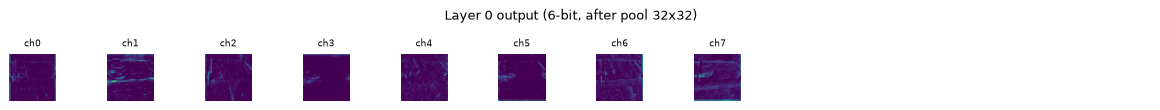

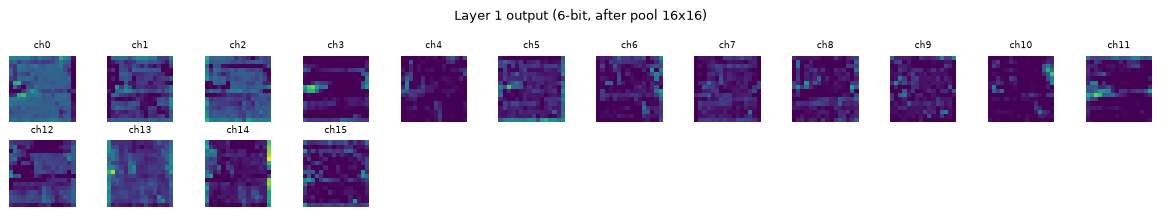

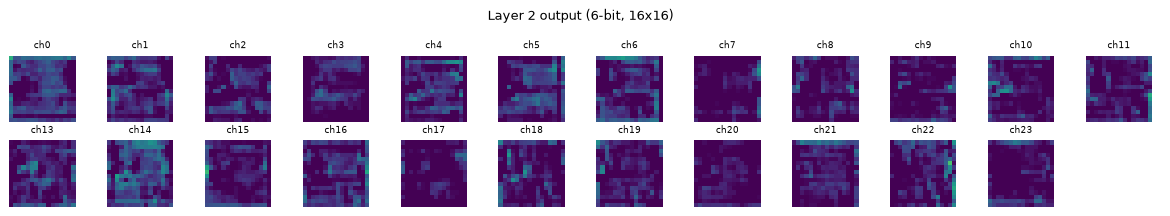

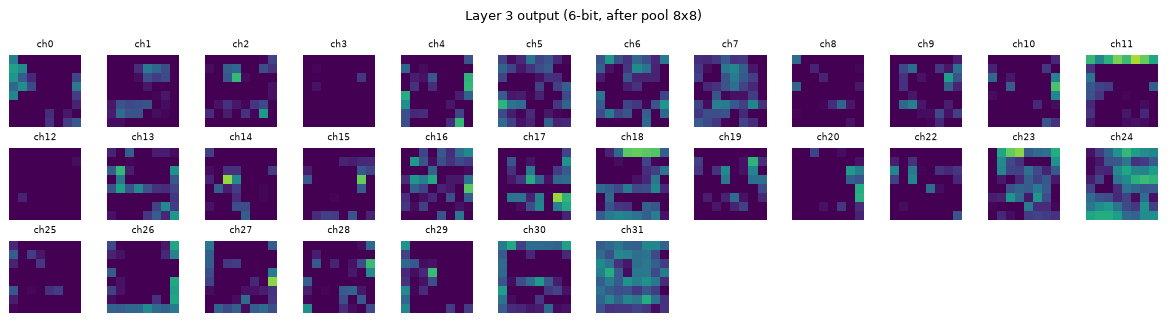

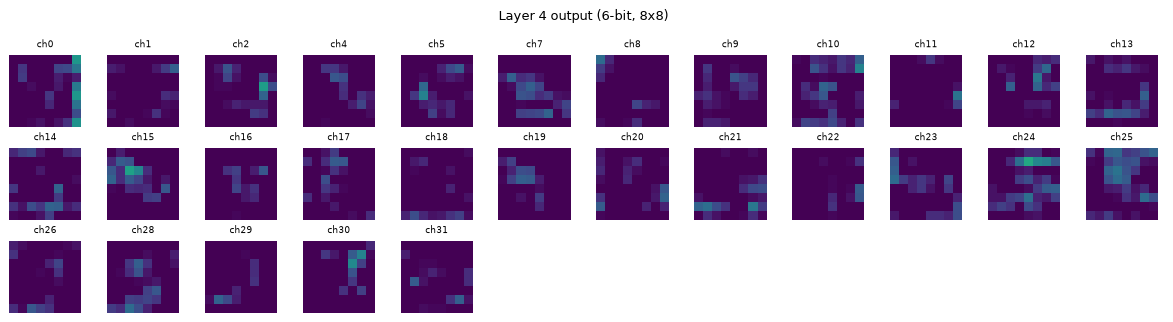

In [10]:
def show_maps(t, i, ncol=12):
    o = t['out'][i][0]
    n = o.shape[0]; nrow = int(math.ceil(n / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(ncol * 1.1, nrow * 1.2))
    for k, a in enumerate(np.atleast_1d(ax).ravel()):
        a.axis('off')
        if k < n:
            a.imshow(o[k], cmap='viridis', vmin=0, vmax=AMAX); a.set_title(f'ch{kept[i][k]}', fontsize=7)
    fig.suptitle(f'Layer {i} output (6-bit, {"after pool " if pools[i] else ""}{o.shape[1]}x{o.shape[2]})', fontsize=10)
    plt.tight_layout(); plt.show()

for i in range(nL):
    show_maps(g1, i)

### Ví dụ một dot-product 3×3 (Fig. 5)
Layer 1, filter đầu tiên còn giữ, kênh vào đầu tiên, điểm ảnh $(5,5)$: 9 cặp (x 6 bit, mã trọng số 4 bit) → dịch bit → cộng.
Sau đó cộng tiếp qua tất cả `Cin` kênh vào và so với `acc` của golden model.

In [11]:
L, co, yy, xx = 1, 0, 5, 5
xin = np.pad(g1['out'][L - 1][0], ((0, 0), (1, 1), (1, 1)))   # input of layer L, zero padded
total = 0
for ci in range(W_int[L].shape[1]):
    win = xin[ci, yy:yy + 3, xx:xx + 3].ravel()
    codes = W_code[L][co, ci].ravel()
    prods = []
    for xv, cv in zip(win, codes):
        s, e = cv >> 3, cv & 7
        p = 0 if e == 0 else (-1 if s else 1) * (int(xv) << (FRAC - e))
        prods.append(p)
    if ci == 0:
        print('  x   code   op              product')
        for xv, cv, p in zip(win, codes, prods):
            s, e = cv >> 3, cv & 7
            op = '0' if e == 0 else f"{'-' if s else '+'}(x << {FRAC - e})"
            print(f"{xv:3d}   {cv:04b}   {op:14s}{p:8d}")
        print('dot (ci=0) =', sum(prods))
    total += sum(prods)
print(f'accumulated over {W_int[L].shape[1]} input channels = {total};  golden acc = {g1["acc"][L][0, co, yy, xx]}')
assert total == g1['acc'][L][0, co, yy, xx]

  x   code   op              product
  8   1111   -(x << 0)           -8
  0   1001   -(x << 6)            0
  0   1010   -(x << 5)            0
  8   1010   -(x << 5)         -256
  0   1001   -(x << 6)            0
  1   1001   -(x << 6)          -64
  7   1101   -(x << 2)          -28
  0   1001   -(x << 6)            0
  0   1001   -(x << 6)            0
dot (ci=0) = -356
accumulated over 8 input channels = 1098;  golden acc = 1098


## 7. Đối chiếu với mô hình PyTorch
Lấy activation sau `ActQ → mask → pool` của mô hình float (`qnn.QNet`), chia cho $s_i$ rồi làm tròn để ra mã 6 bit, sau đó so với golden:
* `ideal`: phần lệch chỉ đến từ thứ tự cộng float32 ở các điểm gần mức làm tròn .5, nên phải rất nhỏ.
* `fixed`: thêm sai số do hệ số $M$ chỉ có `M_BITS` bit. Thử tăng `M_BITS` để thấy phần lệch giảm.

Lỗi lệch ở layer trước sẽ lan sang các layer sau, nên tỉ lệ lệch thường tăng dần theo độ sâu.

In [12]:
model, meta = load_ckpt(CKPT, 'cpu')
model.eval()

@torch.no_grad()
def torch_trace(xu8):
    x = prep(torch.from_numpy(xu8).unsqueeze(1), model.in_bits)
    outs = []
    for i in range(nL):
        x = model.acts[i](model.bns[i](model.convs[i](x))) * model.mask(i).view(1, -1, 1, 1)
        if model.pools[i]:
            x = F.max_pool2d(x, 2)
        outs.append(x.double().numpy())
    lg = model.fc_scale * model.fc(x.mean((2, 3)))
    return outs, lg.double().numpy()

NCMP = 64   # images used for the per-layer comparison
ref_outs, ref_lg = torch_trace(x_u8[:NCMP])
with torch.no_grad():   # sanity: our trace == model.forward
    assert np.allclose(ref_lg, model(prep(torch.from_numpy(x_u8[:NCMP]).unsqueeze(1), model.in_bits)).numpy(), atol=1e-5)

res = {m: golden_forward(X_q[:NCMP], m, trace=True) for m in ('ideal', 'fixed')}
print(f"{'layer':6}{'max |ref/s - round|':>21}{'ideal: mismatch %':>19}{'max|Δ|':>7}{'fixed: mismatch %':>19}{'max|Δ|':>7}")
for i in range(nL):
    r = ref_outs[i][:, kept[i]] / S_act[i]
    rq = np.round(r).astype(np.int64)
    row = f"{i:<6}{np.abs(r - rq).max():>21.2e}"
    for m in ('ideal', 'fixed'):
        d = res[m]['out'][i] - rq
        row += f"{100 * (d != 0).mean():>18.4f}%{np.abs(d).max():>7d}"
    print(row)
for m in ('ideal', 'fixed'):
    print(f"logits max |golden - torch| ({m}): {np.abs(res[m]['logits'] - ref_lg).max():.2e}")

layer   max |ref/s - round|  ideal: mismatch % max|Δ|  fixed: mismatch % max|Δ|
0                  1.85e-06            0.0000%      0            0.0000%      0
1                  1.85e-06            0.0004%      1            0.0088%      1
2                  1.85e-06            0.0021%      1            0.0448%      1
3                  1.85e-06            0.0071%      1            0.3363%      2
4                  1.85e-06            0.0059%      1            0.5725%      1
logits max |golden - torch| (ideal): 2.28e-03
logits max |golden - torch| (fixed): 2.28e-02


## 8. Toàn bộ tập test: golden (fixed-point) vs PyTorch
Quyết định của PyTorch: `score > thr` với `score = logit1 - logit0` (giống `main.py eval`). Quyết định của golden: `D > T` (chỉ dùng số nguyên).
Kết quả PyTorch nên khớp với `acc_tuned` trong `runs/iter_p2w4a6_in4/eval.json`.

images 921
PyTorch  acc@thr  0.7459
golden   acc@T    0.7448   (argmax: 0.7427)
decision agreement golden vs torch: 99.89%  (1 images differ)
eval.json acc_tuned: 0.743756786102063

accumulator range over the whole test set:
  layer 0: [-2688, 2528] -> 13 bit
  layer 1: [-29782, 25820] -> 16 bit
  layer 2: [-62680, 37440] -> 17 bit
  layer 3: [-60078, 35950] -> 17 bit
  layer 4: [-69480, 64901] -> 18 bit
  FC D: [-201056, 350656] -> 20 bit,  T = 2688


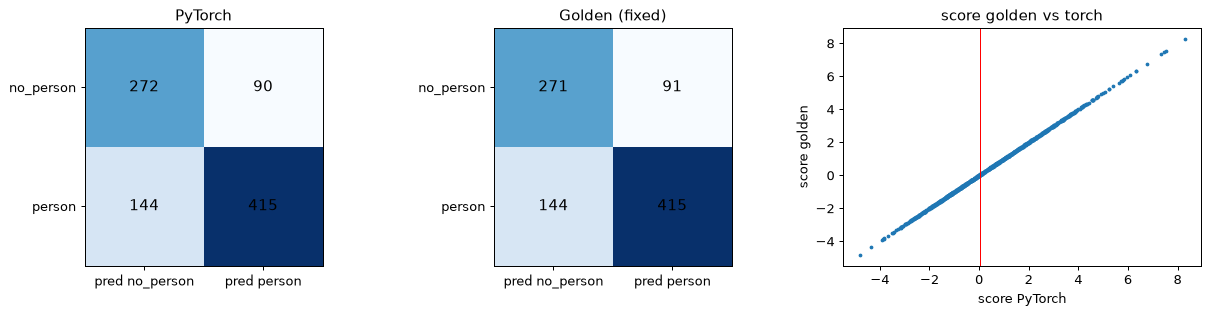

In [13]:
def run_all(mode, bs=128):
    D, P, P0, lg = [], [], [], []
    acc_lo = np.zeros(nL, np.int64); acc_hi = np.zeros(nL, np.int64)
    for s in range(0, len(X_q), bs):
        t = golden_forward(X_q[s:s + bs], mode)
        D.append(t['D']); P.append(t['pred']); P0.append(t['pred_argmax']); lg.append(t['logits'])
        for i, (lo, hi) in enumerate(t['acc']):
            acc_lo[i] = min(acc_lo[i], lo); acc_hi[i] = max(acc_hi[i], hi)
    return dict(D=np.concatenate(D), pred=np.concatenate(P), pred0=np.concatenate(P0),
                logits=np.concatenate(lg), acc_lo=acc_lo, acc_hi=acc_hi, T=t['T'])

G = run_all('fixed')
with torch.no_grad():
    lg = torch.cat([model(prep(torch.from_numpy(x_u8[s:s + 256]).unsqueeze(1), model.in_bits))
                    for s in range(0, len(x_u8), 256)]).double().numpy()
score_ref = lg[:, 1] - lg[:, 0]
pred_ref = (score_ref > THR).astype(np.int64)

def cm(pred, y):
    return np.array([[((y == 0) & (pred == 0)).sum(), ((y == 0) & (pred == 1)).sum()],
                     [((y == 1) & (pred == 0)).sum(), ((y == 1) & (pred == 1)).sum()]])

y = y_all
print(f"images {len(y)}")
print(f"PyTorch  acc@thr  {(pred_ref == y).mean():.4f}")
print(f"golden   acc@T    {(G['pred'] == y).mean():.4f}   (argmax: {(G['pred0'] == y).mean():.4f})")
print(f"decision agreement golden vs torch: {(G['pred'] == pred_ref).mean() * 100:.2f}%  "
      f"({int((G['pred'] != pred_ref).sum())} images differ)")
ev = os.path.join(HERE, 'runs/iter_p2w4a6_in4/eval.json')
if os.path.exists(ev):
    print('eval.json acc_tuned:', json.load(open(ev))['metrics']['acc_tuned'])

print('\naccumulator range over the whole test set:')
for i in range(nL):
    print(f"  layer {i}: [{G['acc_lo'][i]}, {G['acc_hi'][i]}] -> {sbits(G['acc_lo'][i], G['acc_hi'][i])} bit")
print(f"  FC D: [{G['D'].min()}, {G['D'].max()}] -> {sbits(G['D'].min(), G['D'].max())} bit,  T = {G['T']}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (name, p) in zip(ax[:2], [('PyTorch', pred_ref), ('Golden (fixed)', G['pred'])]):
    m = cm(p, y); a.imshow(m, cmap='Blues')
    for (r, c), v in np.ndenumerate(m): a.text(c, r, v, ha='center', va='center', fontsize=12)
    a.set_xticks([0, 1]); a.set_xticklabels(['pred no_person', 'pred person'])
    a.set_yticks([0, 1]); a.set_yticklabels(['no_person', 'person']); a.set_title(name)
ax[2].scatter(score_ref, G['logits'][:, 1] - G['logits'][:, 0], s=4)
ax[2].axvline(THR, c='r', lw=.8); ax[2].set_xlabel('score PyTorch'); ax[2].set_ylabel('score golden'); ax[2].set_title('score golden vs torch')
plt.tight_layout(); plt.show()

## 9. Xuất test vector cho RTL
Thư mục `golden_out/`. Mỗi file `.hex` ghi một giá trị trên một dòng (bù 2 cho số âm), dùng được với `$readmemh`.

| File | Nội dung | Thứ tự |
|---|---|---|
| `params.json` | kiến trúc, kênh giữ lại, `SH`, `c`, `T`, độ rộng bit | |
| `w_L{i}.hex` | mã trọng số 4 bit `[s e2 e1 e0]` | `[cout][cin][ky][kx]` |
| `bn_M_L{i}.hex`, `bn_B_L{i}.hex` | $M$ (`M_BITS`), $B_q$ (`BQ_BITS`) | `[cout]` |
| `fc_w.hex` | mã trọng số FC 4 bit | `[class][cin]` |
| `img{k}_in.hex` | pixel 4 bit | `[y][x]` |
| `img{k}_acc_L{i}.hex` | accumulator (trước requant), 32 bit | `[c][y][x]` |
| `img{k}_out_L{i}.hex` | mã activation 6 bit sau pool | `[c][y][x]` |
| `img{k}_fc.hex` | $S_c$ (32 bit) rồi $acc^{fc}_0, acc^{fc}_1, D$ | |

In [14]:
def write_hex(path, vals, bits):
    v = np.asarray(vals, dtype=np.int64).ravel()
    m, w = (1 << bits) - 1, (bits + 3) // 4
    with open(path, 'w') as f:
        f.write('\n'.join(f'{int(x) & m:0{w}x}' for x in v) + '\n')

EXPORT_IMGS = list(dict.fromkeys([SAMPLE_IDX, int(np.nonzero(y_all == 1)[0][0]), int(np.nonzero(y_all == 0)[0][0])]))
os.makedirs(OUT_DIR, exist_ok=True)
for i in range(nL):
    write_hex(f'{OUT_DIR}/w_L{i}.hex', W_code[i], 4)
    write_hex(f'{OUT_DIR}/bn_M_L{i}.hex', BN[i]['M'], M_BITS)
    write_hex(f'{OUT_DIR}/bn_B_L{i}.hex', BN[i]['Bq'], BQ_BITS)
write_hex(f'{OUT_DIR}/fc_w.hex', FC_code, 4)

params = dict(arch=ck['arch'], kept=[len(k) for k in kept], kept_idx=[k.tolist() for k in kept], pools=pools,
              in_bits=IN_BITS, abits=ABITS, w_frac=FRAC, m_bits=M_BITS, bq_bits=BQ_BITS,
              SH=[d['SH'] for d in BN], clip=C_clip, T=int(G['T']), T_argmax=int(res['fixed']['T0']),
              requant='q = clamp((acc*M + Bq) >>> SH, 0, 63)', decision='person if D = acc_fc1 - acc_fc0 > T',
              weight_code='[s e2 e1 e0], |w| = 2^-e, e=0 -> 0; product = ±(x << (7-e))',
              images=[dict(idx=k, label=int(y_all[k])) for k in EXPORT_IMGS])

for k in EXPORT_IMGS:
    t = golden_forward(X_q[k:k + 1], 'fixed', trace=True)
    write_hex(f'{OUT_DIR}/img{k}_in.hex', X_q[k, 0], IN_BITS)
    for i in range(nL):
        write_hex(f'{OUT_DIR}/img{k}_acc_L{i}.hex', t['acc'][i][0], 32)
        write_hex(f'{OUT_DIR}/img{k}_out_L{i}.hex', t['out'][i][0], ABITS)
    write_hex(f'{OUT_DIR}/img{k}_fc.hex', np.r_[t['S'][0], t['acc_fc'][0], t['D']], 32)
    params['images'][EXPORT_IMGS.index(k)].update(D=int(t['D'][0]), pred=int(t['pred'][0]))

json.dump(params, open(f'{OUT_DIR}/params.json', 'w'), indent=1)
print('wrote', len(os.listdir(OUT_DIR)), 'files to', OUT_DIR)
print(json.dumps(params['images'], indent=1))

wrote 41 files to /home/mpeclab/Downloads/sw/commit_folder/golden_out
[
 {
  "idx": 0,
  "label": 0,
  "D": 3200,
  "pred": 1
 },
 {
  "idx": 362,
  "label": 1,
  "D": 33280,
  "pred": 1
 }
]


## Ghi chú
* Đổi `SAMPLE_IDX` ở ô đầu để theo dõi ảnh khác. Đổi `M_BITS` (12, 14, 20 …) để xem độ chính xác của phần requant thay đổi thế nào.
* Golden model **không** import `qnn.model` để tính toán; nó chỉ dùng `numpy` trên `state_dict`. `qnn` chỉ được dùng để nạp ảnh và để chạy mô hình tham chiếu PyTorch.
* Otsu-thresholding (paper, SVHN) không dùng ở đây vì đầu vào là ảnh xám 4 bit.